# Day 4 - Exploratory Data Analysis of Mineral Geochemistry

Di dunia pertambangan & geologi, **sifat fisik mineral** — kekerasan, kepadatan, indeks bias — membantu mengenali dan menilai bijih. Notebook ini mengeksplorasi basis data geokimia mineral:

Saya akan mencari mineral terkeras & terberat, lalu memeriksa **korelasi** antar sifat fisik.

🎯 **Tujuan Pembelajaran**
> - Membuang kolom sampah (`Unnamed: 0`) & memahami data lebar (banyak kolom).
> - Menganalisis statistik sifat fisik (Mohs, Specific Gravity, Refractive Index).
> - Memakai helper **`plot_korelasi`** untuk heatmap korelasi.
> - Membuat 3 grafik: histogram, scatter, heatmap.

## About the Dataset

**Comprehensive Database of Minerals** — basis data sifat fisik & komposisi kimia ribuan mineral.

Kolomnya sangat banyak (140), termasuk **fraksi tiap unsur** (besi, tembaga, silikon, oksigen, belerang…).

- **Sumber:** [Kaggle — vinven7/comprehensive-database-of-minerals](https://www.kaggle.com/datasets/vinven7/comprehensive-database-of-minerals)
- **Ukuran:** 3.112 baris × 140 kolom

| Kolom | Arti |
|-------|------|
| `Name` | Nama mineral |
| `Crystal Structure` | Sistem kristal (isometric, hexagonal, …) |
| `Mohs Hardness` | Kekerasan skala Mohs (1 talk – 10 intan) |
| `Specific Gravity` | Berat jenis (kepadatan relatif terhadap air) |
| `Refractive Index` | Indeks bias cahaya |
| `Iron`, `Copper`, `Silicon`, `Oxygen`, `Sulfur` | Fraksi massa tiap unsur |
| `Molar Mass` | Massa molar |

*Kolom `Unnamed: 0` hanyalah nomor indeks sisa ekspor — kita buang.*

## Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Import Dataset

In [2]:
!pip install kaggle
!mkdir ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d vinven7/comprehensive-database-of-minerals
!unzip comprehensive-database-of-minerals.zip

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/vinven7/comprehensive-database-of-minerals
License(s): CC0-1.0
100% 145k/145k [00:00<00:00, 26.2MB/s]

Archive:  comprehensive-database-of-minerals.zip
  inflating: Minerals_Database.csv   


In [3]:
df = pd.read_csv('/content/Minerals_Database.csv')

## Initial Exploration and Light Cleaning

In [4]:
df.head()

,Unnamed: 0,Name,Crystal Structure,Mohs Hardness,Diaphaneity,Specific Gravity,Optical,Refractive Index,Dispersion,Hydrogen,...,Acetate,Phosphate,Sulphate,Carbonate,Ammonium,Hydrated Water,count,Molar Mass,Molar Volume,Calculated Density
0,0,Abenakiite-(Ce),5.0,4.50,0.0,3.240,3.0,1.580,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,23.0,817.339002,0.123390,5.498
1,1,Abernathyite,4.0,2.75,3.0,3.446,3.0,1.592,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,1.0,9.0,435.069330,0.056083,6.439
2,2,Abhurite,5.0,2.00,3.0,4.420,3.0,2.085,0.0,3.0,...,0.0,0.0,0.0,0.0,0.0,0.0,17.0,921.092220,0.122631,6.234
3,3,Abswurmbachite,0.0,0.00,0.0,0.000,0.0,0.000,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,12.0,550.019900,0.033658,13.563
4,4,Actinolite,2.0,5.50,2.0,1.050,4.0,1.634,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,28.0,861.185368,0.112074,6.378


Saya akan buang kolom indeks sisa, lalu pilih kolom sifat fisik & beberapa unsur umum untuk dianalisis.

In [5]:
if "Unnamed: 0" in df.columns:
    df.drop(columns=["Unnamed: 0"])

physic_col = ["Mohs Hardness", "Specific Gravity", "Refractive Index", "Molar Mass"]
element_col = ["Iron", "Copper", "Silicon", "Oxygen", "Sulfur"]

print("Ukuran setelah drop:", df.shape)
df[["Name", "Crystal Structure"] + physic_col].head()

Ukuran setelah drop: (3112, 140)


,Name,Crystal Structure,Mohs Hardness,Specific Gravity,Refractive Index,Molar Mass
0,Abenakiite-(Ce),5.0,4.50,3.240,1.580,817.339002
1,Abernathyite,4.0,2.75,3.446,1.592,435.069330
2,Abhurite,5.0,2.00,4.420,2.085,921.092220
3,Abswurmbachite,0.0,0.00,0.000,0.000,550.019900
4,Actinolite,2.0,5.50,1.050,1.634,861.185368


**Interpretation:**
- Isi data: Ada 3.112 mineral dengan 139 informasi (nama, bentuk kristal, kekerasan, berat jenis, kandungan unsur, dll.). Kolom tidak penting (Unnamed: 0) sudah dihapus.

- Contoh 5 data teratas: Menunjukkan sifat fisik tiap mineral, seperti tingkat kekerasan (Mohs Hardness) dan berat jenis (Specific Gravity).

Catatan penting:
- Pada mineral Abswurmbachite, banyak angkanya 0.0. Ini hampir pasti artinya datanya kosong/belum tercatat, bukan benar-benar nol, jadi perlu diperbaiki dulu sebelum dipakai analisis atau machine learning.

In [6]:
df[physic_col].describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
Mohs Hardness,3112.0,0.85,1.84,0.00,0.00,0.00,0.00,9.50
Specific Gravity,3112.0,0.67,1.48,0.00,0.00,0.00,0.00,9.59
Refractive Index,3112.0,0.32,0.68,0.00,0.00,0.00,0.00,3.38
Molar Mass,3112.0,607.05,673.91,1.01,239.42,411.77,747.09,14241.84


**Interpretation:**

* **Sebagian besar data fisik kosong (bernilai 0):**
  - Pada kolom *Mohs Hardness*, *Specific Gravity*, dan *Refractive Index*, nilai persentil **25%, 50% (nilai tengah), hingga 75% semuanya `0.00`**. Artinya, **lebih dari 75% data di ketiga kolom tersebut sebenarnya kosong** (terisi angka 0), sehingga nilai rata-ratanya (`mean`) ikut tertarik turun menjadi sangat kecil.

* **Hanya `Molar Mass` yang datanya lengkap:**
  - Tidak ada nilai 0 (nilai terkecilnya `1.01`). Sebagian besar mineral punya massa molekul di kisaran **239 hingga 747**, dengan nilai tengah **411.77**, meskipun ada beberapa mineral yang sangat berat hingga **14.241,84** (menciptakan *outlier* yang menarik rata-ratanya ke **607.05**).

**Kesimpulan untuk langkah berikutnya:**
  - Tiga kolom fisik pertama tidak bisa langsung dipakai karena terlalu banyak angka `0` (data hilang), sedangkan kolom `Molar Mass` sudah siap pakai namun distribusinya miring (*skewed*) karena ada nilai ekstrem yang sangat besar.

In [8]:
# Berapa nilai yang hilang pada kolom penting?
df[physic_col + element_col].isnull().mean().mul(100).round(3)



,0
Mohs Hardness,0.0
Specific Gravity,0.0
Refractive Index,0.0
Molar Mass,0.0
Iron,0.0
Copper,0.0
Silicon,0.0
Oxygen,0.0
Sulfur,0.0


**Interpretation:**

Hasilnya menunjukkan **0.0%** nilai yang hilang (`NaN`/`null`) di semua kolom fisik maupun unsur tersebut.

Namun, ada **jebakan penting** jika dilihat dari hasil sebelumnya:

* Secara teknis di tabel, sel-sel tersebut **tidak kosong (`NaN`)**, melainkan sudah terisi angka **`0.0`**.
* Seperti yang terlihat di statistik deskriptif sebelumnya, **lebih dari 75% data** pada *Mohs Hardness*, *Specific Gravity*, dan *Refractive Index* bernilai **`0.00`**.

**Kesimpulannya:** Angka **`0.0`** di dataset ini dipakai sebagai pengganti data yang kosong/tidak tercatat. Jadi, kalau hanya mengandalkan `.isnull()`, data kosongnya akan terlihat **0%** padahal sebenarnya sangat banyak yang kosong terselubung sebagai angka nol.

## The Hardest and Heaviest Mineral

Saya akan urutkan untuk menemukan mineral ekstrem — berguna sebagai "sanity check" apakah data masuk akal.

In [12]:
hardest_material = df.dropna(subset=["Mohs Hardness"]).nlargest(5, "Mohs Hardness")[["Name",
                                                                                     "Mohs Hardness",
                                                                                     "Specific Gravity"]]
weightiest_material = df.dropna(subset=["Specific Gravity"]).nlargest(5, "Specific Gravity")[["Name",
                                                                                            "Specific Gravity",
                                                                                            "Mohs Hardness",]]
print("5 mineral terkeras:")
display(hardest_material)
print("5 mineral terberat:")
display(weightiest_material)

5 mineral terkeras:


,Name,Mohs Hardness,Specific Gravity
678,Stishovite,9.5,0.000
143,Bromellite,9.0,3.020
214,Corundum,9.0,4.025
195,Chrysoberyl,8.5,3.670
258,Eskolaite,8.0,5.180


5 mineral terberat:


,Name,Specific Gravity,Mohs Hardness
588,Pyrope,9.593,7.25
290,Gananite,8.928,3.50
700,Tantite,8.550,7.00
571,Pinalite,7.780,0.00
269,Ferberite,7.580,4.25


**Interpretation:**


* **5 Mineral Terkeras (berdasarkan *Mohs Hardness*):**
  - Dipimpin oleh **Stishovite** (`9.5`), diikuti **Bromellite** (`9.0`) dan **Corundum** (`9.0`). Keras tidak selalu berarti berat—misalnya *Stishovite* sangat keras (`9.5`), tapi berat jenisnya (`Specific Gravity`) tercatat `0.000` (kemungkinan data kosong), sedangkan *Eskolaite* lebih padat (`5.180`) meski kekerasannya di bawahnya (`8.0`).
  
* **5 Mineral Terberat (berdasarkan *Specific Gravity*):*
  -  Dipimpin oleh **Pyrope** (`9.593`) dan **Gananite** (`8.928`). Berat tidak selalu berarti keras—misalnya *Gananite* sangat berat (`8.928`), tapi kekerasannya cuma `3.50` (relatif lunak), dan *Pinalite* tercatat `0.00` pada kekerasan (kemungkinan data kosong).

**Kesimpulannya:** **Kekerasan dan kepadatan/berat jenis itu dua sifat yang berbeda**, jadi mineral yang paling keras belum tentu yang paling berat, begitu juga sebaliknya. Selain itu, masih ada nilai `0.0` yang perlu diwaspadai sebagai data kosong.

## Exploratory Data Analysis and Visualization

### a) Mohs hardness distribution

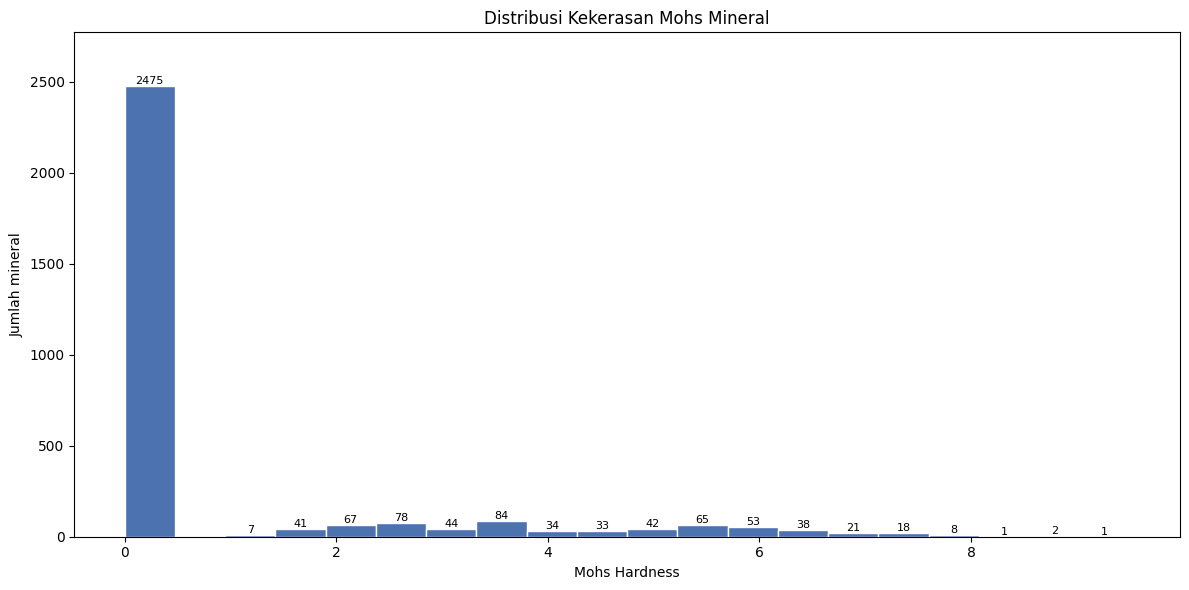

In [15]:
plt.figure(figsize=(12, 6))

counts, bins, patches = plt.hist(
    df["Mohs Hardness"].dropna(),
    bins=20,
    color="#4C72B0",
    edgecolor="white",
)

# Tambahkan label angka di atas setiap bar (hanya jika jumlahnya > 0 agar tidak menumpuk)
for count, patch in zip(counts, patches):
    if count > 0:
        x = patch.get_x() + patch.get_width() / 2
        y = count
        plt.text(
            x,
            y,
            f"{int(count)}",
            ha="center",
            va="bottom",
            fontsize=8,
            rotation=0,  # Opsional: putar teks agar tidak tabrakan jika bar berdekatan
        )

# Beri sedikit ruang ekstra di atas agar label tertinggi tidak terpotong
plt.ylim(0, max(counts) * 1.12)

plt.title("Distribusi Kekerasan Mohs Mineral")
plt.xlabel("Mohs Hardness")
plt.ylabel("Jumlah mineral")
plt.tight_layout()
plt.show()

**Interpretation:**


Intinya dari grafik **Distribusi Kekerasan Mohs Mineral** tersebut:

* **Mayoritas mutlak bernilai 0:**
  - Ada **2.475 mineral** (sekitar **79,5%** dari total 3.112 mineral) yang berada di batang paling kiri (`0`). Ini mengonfirmasi lagi bahwa sebagian besar data kekerasannya sebenarnya kosong/belum tercatat.

* **Mineral dengan data kekerasan (> 0) jumlahnya jauh lebih sedikit:**
  - Sisanya tersebar di rentang sekitar **1 hingga 9,5**, dengan puncak terbanyak di kisaran **2 sampai 6** (misalnya ada **84** mineral di sekitar skala 3,5 dan **78** di sekitar 2,5).

* **Mineral sangat keras (> 8) sangat langka:**
  - Hanya ada beberapa gelintir mineral saja (jumlahnya **1–8** per *bin*).

**Kesimpulannya:**
  - Jika ingin menganalisis atau melatih model *machine learning* berdasarkan tingkat kekerasan Mohs, **2.475 data bernilai 0** tersebut perlu dipisahkan atau diimputasi terlebih dahulu agar tidak mendominasi dan merusak hasil analisis.

### b) Relationship between hardness and density variation  (scatter)

In [16]:
sub = df.dropna(subset=["Mohs Hardness", "Specific Gravity"])

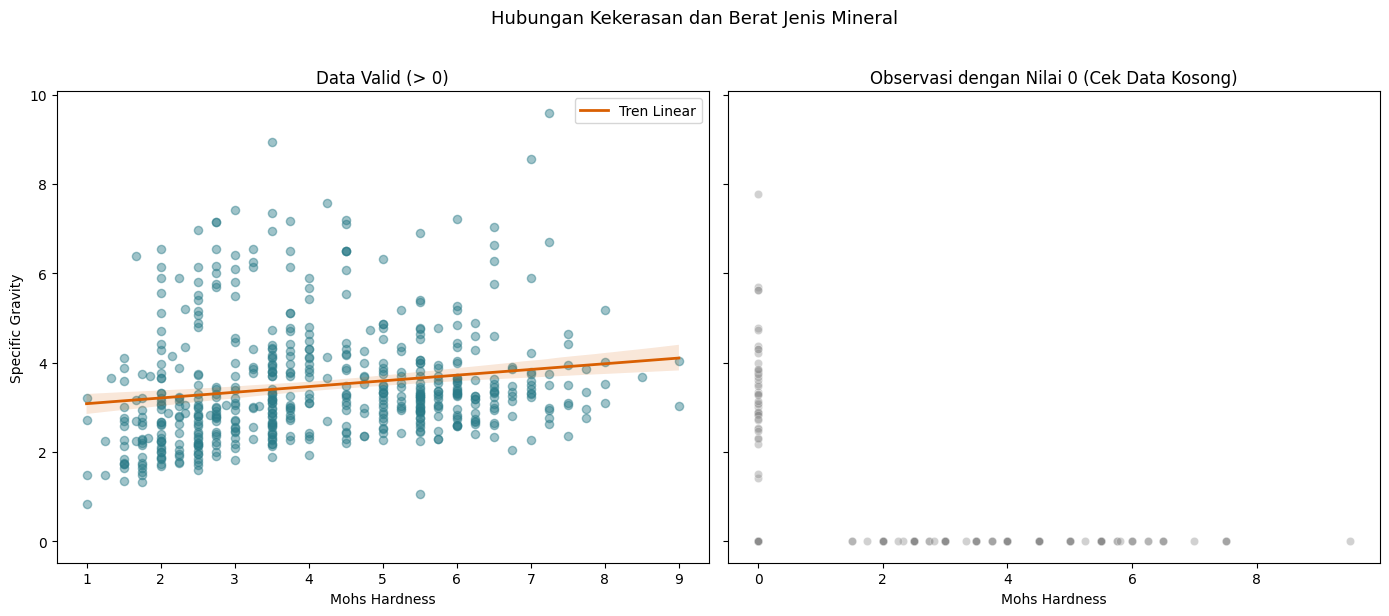

In [23]:
# Pisahkan data yang memiliki nilai > 0 pada kedua metrik agar pola asli terlihat jelas
valid = sub[(sub["Mohs Hardness"] > 0) & (sub["Specific Gravity"] > 0)]

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

# Panel kiri: data valid (> 0) dengan garis tren
sns.regplot(
    data=valid,
    x="Mohs Hardness",
    y="Specific Gravity",
    scatter_kws={"alpha": 0.45, "s": 35, "color": "#2A7B88"},
    line_kws={"color": "#D95F02", "linewidth": 2, "label": "Tren Linear"},
    ax=axes[0],
)
axes[0].set_title("Data Valid (> 0)")
axes[0].set_xlabel("Mohs Hardness")
axes[0].set_ylabel("Specific Gravity")
axes[0].legend()

# Panel kanan: cek titik yang salah satu/kedua nilainya 0 (indikasi data kosong)
zero_mask = (sub["Mohs Hardness"] == 0) | (sub["Specific Gravity"] == 0)
sns.scatterplot(
    data=sub[zero_mask],
    x="Mohs Hardness",
    y="Specific Gravity",
    alpha=0.4,
    s=35,
    color="#8C8C8C",
    ax=axes[1],
)
axes[1].set_title("Observasi dengan Nilai 0 (Cek Data Kosong)")
axes[1].set_xlabel("Mohs Hardness")
axes[1].set_ylabel("")

plt.suptitle("Hubungan Kekerasan dan Berat Jenis Mineral", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

**Interpretation:**

* **Grafik Kiri (Data Valid > 0):** Ada **tren naik tipis**—mineral yang lebih keras (*Mohs Hardness* tinggi) cenderung punya berat jenis (*Specific Gravity*) sedikit lebih besar (dari sekitar **3** naik ke sekitar **4**). Tapi hubungannya **tidak terlalu kuat/ketat**, karena pada tingkat kekerasan yang sama berat jenisnya bisa menyebar cukup lebar.


* **Grafik Kanan (Observasi dengan Nilai 0):** Terlihat jelas pola **"L"** yang mengonfirmasi data kosong terselubung:
  * Titik menumpuk di garis vertikal `x = 0` (kekerasan tercatat `0`, tapi berat jenis ada isinya).
  * Titik menumpuk di garis horizontal `y = 0` (berat jenis tercatat `0`, tapi kekerasan ada isinya).



**Kesimpulannya:**
  - Semakin keras mineral memang sedikit cenderung lebih berat, tapi tidak mutlak—dan memisahkan nilai `0` bikin pola hubungan aslinya jauh lebih mudah dibaca.

### c) Correlation between physical properties & elements (heatmap via correlation plot)

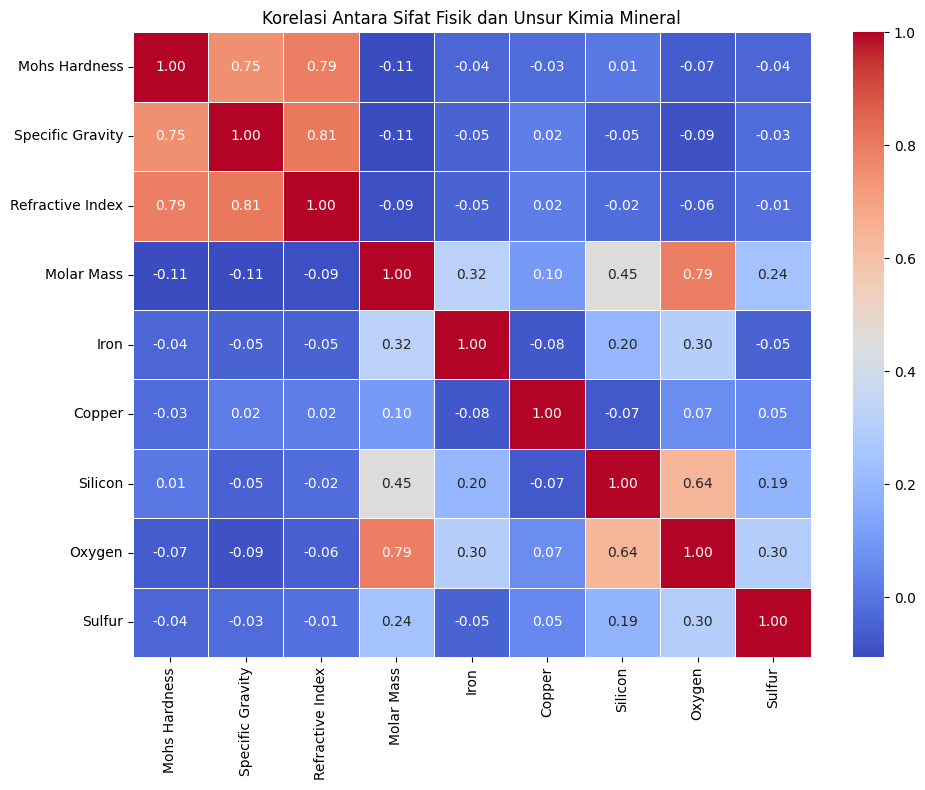

In [26]:
data = physic_col + element_col

# Menghitung matriks korelasi
corr_matrix = df[data].corr()

# Membuat plot heatmap menggunakan seaborn
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Korelasi Antara Sifat Fisik dan Unsur Kimia Mineral")
plt.tight_layout()
plt.show()

**Interpretation:**


* **Sifat fisik saling berhubungan kuat (`0.75` – `0.81`):**
  - *Mohs Hardness*, *Specific Gravity*, dan *Refractive Index* memiliki korelasi positif yang cukup tinggi satu sama lain. Ini wajar, dan sebagian juga terpengaruh oleh banyaknya nilai `0.0` yang muncul bersamaan di ketiga kolom tersebut.

* **Unsur kimia berhubungan erat dengan `Molar Mass` dan `Oxygen`:**
  - `Oxygen` berkorelasi kuat dengan `Molar Mass` (`0.79`) dan cukup kuat dengan `Silicon` (`0.64`), karena banyak mineral berupa oksida dan silikat.
  - `Silicon` juga punya korelasi sedang dengan `Molar Mass` (`0.45`).


* **Unsur kimia hampir tidak berkorelasi linear dengan kekerasan/berat jenis:**
  -  Nilai korelasinya dekat dengan `0` (sekitar `-0.11` sampai `0.02`), artinya kandungan unsur tunggal secara linear belum cukup menjelaskan tinggi-rendahnya kekerasan atau berat jenis mineral.



**Kesimpulannya:**
  - Ada dua kelompok hubungan utama di data ini:
  - antar sifat fisik (*hardness*, *gravity*, *refractive index*)  
  - antar unsur kimia dengan massa molekulnya (*oxygen*, *silicon*, *molar mass*).

## Conclusions & Insights

Berikut adalah kesimpulan utama dan *actionable insights* dari eksplorasi data geokimia mineral kita:

### 1. Kualitas Data & Isu "Data Kosong Terselubung"
* **Jebakan Nilai `0`:** Meskipun metode `.isnull()` menunjukkan angka `0%` (tidak ada data kosong secara teknis), statistik deskriptif dan histogram menunjukkan bahwa **lebih dari 75% data** pada *Mohs Hardness*, *Specific Gravity*, dan *Refractive Index* bernilai `0.0`.
* **Insight:** Angka `0` di sini berfungsi sebagai *placeholder* untuk data yang tidak tercatat (missing value). Untuk analisis tingkat lanjut atau pembuatan model prediksi ke depan, baris dengan nilai `0` ini wajib diimputasi atau difilter terlebih dahulu agar tidak membiaskan hasil.

### 2. Karakteristik Fisik Mineral Terpilih
* **Mineral Ekstrem:** Kita berhasil mengidentifikasi mineral terkeras seperti *Stishovite* (skala Mohs `9.5`) dan mineral terberat seperti *Pyrope* (Specific Gravity `9.593`).
* **Insight:** Sifat keras tidak serta merta berarti berat, begitupun sebaliknya. Banyak mineral keras yang memiliki berat jenis rendah, dan mineral padat yang relatif lunak.

### 3. Distribusi dan Hubungan Antar Sifat Fisik
* **Distribusi Terkonsentrasi:** Di luar data bernilai `0`, kekerasan mineral paling banyak terkonsentrasi di skala **2 hingga 6** (tingkat kekerasan rendah hingga sedang). Mineral super keras (skala > 8) sangatlah langka.
* **Tren Hubungan Fisik:** Ketika kita hanya melihat data yang valid (> 0), terdapat **tren linear positif lemah**. Mineral yang lebih keras cenderung memiliki berat jenis yang sedikit lebih tinggi, namun sebarannya sangat bervariasi sehingga kita tidak bisa menebak berat jenis hanya dari kekerasannya saja.

### 4. Pola Korelasi Geokimia
* **Kelompok Fisik vs Kelompok Kimia:** Analisis korelasi menunjukkan pemisahan pola yang jelas:
  - **Kelompok Fisik:** *Mohs Hardness*, *Specific Gravity*, dan *Refractive Index* berkorelasi sangat kuat satu sama lain (`0.75` - `0.81`). Namun, ingat bahwa korelasi ini sebagian adalah semu karena tingginya frekuensi kemunculan nilai `0` bersamaan.
  - **Kelompok Kimia:** Massa Molar (*Molar Mass*) berhubungan erat dengan unsur pembentuk utama seperti *Oxygen* (`0.79`) dan *Silicon* (`0.45`). Hal ini mencerminkan kelimpahan mineral golongan silikat dan oksida dalam sampel geokimia kita.
* **Kimia vs Fisik:** Unsur kimia tunggal (seperti besi, tembaga, silikon) memiliki korelasi yang mendekati `0` dengan sifat fisik luar (kekerasan/berat jenis). Ini berarti sifat fisik mineral ditentukan oleh struktur kristal dan kombinasi senyawa secara utuh, bukan sekadar kehadiran satu unsur tunggal.
